# 5. Single-step cavity circuit test — Python

Follow the same workflow as tests 1–4:

1. Edit the visible inputs and **Restart Kernel and Run All** here.
2. Run all sections of `cavity_circuit_test.mlx` (or the readable `.m` source).
3. Run `compare_results.ipynb`.

Each language independently builds the Gaussian maps, grid, prescribed beam excitation, and global circuit system. This tests input, bunching and output cavities together, with optional direct coupling.

This is **one fixed-frequency circuit solve with a prescribed beam**, not nonlinear convergence or particle tracking. Scaled RF fields below are a **test-only reconstruction from the solved modal voltages**, checked against MATLAB's gap-voltage formula. They are not a claim that the original solver's `Emz` update is implemented. No production classes are changed.


In [1]:
# Import necessary libraries and modules

from pathlib import Path
import sys
from dataclasses import replace
from uuid import uuid4

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat
from IPython.display import Markdown, display


In [2]:
# Import custom modules and classes to be tested

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "5.cavity_circuit_test"
sys.path.insert(0, str(project_directory / "src"))

from constants import c, etom, mu01, eta0, esign
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters
from solver.beam_state import BeamState

from model.cavity_field_map import CavityFieldMap
from solver.cavity_fields import CavityFields
from solver.cavity_state import CavityState


In [3]:
# Set global options for numpy and matplotlib

np.set_printoptions(precision=6, linewidth=140)
# Apply the same dashed gray grid to every subplot.
# "line" places the grid above shaded regions, but below plotted lines.
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})

# Display options for Jupyter Notebook Tables

def show_table(rows):
    text = "| Variable | Value | Units | Meaning |\n"
    text += "|---|---|---|---|\n"
    for name, value, units, meaning in rows:
        if isinstance(value, np.ndarray):
            value = np.array2string(value, precision=5, max_line_width=1000)
        elif isinstance(value, (float, np.floating)):
            value = f"{value:.8g}"
        text += f"| `{name}` | {value} | {units} | {meaning} |\n"
    display(Markdown(text))


## 1. Editable inputs

The five-cavity fixture uses the manual's 1 GHz operating frequency and resonances `[1.000, 1.006, 1.016, 1.030, 1.000]` GHz. All beam presets have the same mean current (−16 A) and constant energy (180 kV).

- `uniform`: no RF beam excitation, apart from floating-point roundoff.
- `modulated`: weak sinusoidal current modulation.
- `bunched`: smooth, positive, periodic bunches, proportional to `exp(bunch_strength*cos(t0-bunch_phase))`, normalized to the same mean current. This is a prescribed distribution, not bunching computed by the solver.

`beam_transport="initial_guess"` reproduces the longitudinally constant initialization of the original solver. `"constant_speed"` analytically advances the bunch phase along the tube without changing its shape or speed. This makes transit-time phase cancellation visible in the beam-drive integral. It deliberately ignores the response of the beam to the fields being solved.

Set `Pin[0]=0` for a beam-only test. Nonzero off-diagonal `kai` tests coupled circuits. Coupled cavities must operate at the same harmonic. `gaman` is the output-port reflection coefficient; `M` is the Gaussian transit-time factor, not inter-cavity coupling.


In [5]:
case_name = "bunched"  # "uniform", "modulated", or "bunched"
beam_transport = "constant_speed"  # or "initial_guess"
bunch_strength = 3.0
bunch_phase = 0.60
arrival_phase = 0.35

# Beam: sample weights over one RF period, with constant energy.
Nbeam = 1
rm1, rm2, rc = 0.0, 6.0, 10.0
Nt = 256
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0 + arrival_phase
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)

if case_name == "uniform":
    weights = np.ones(Nt)
elif case_name == "modulated":
    weights = 1.0 + 0.20 * np.cos(t0 - bunch_phase)
elif case_name == "bunched":
    weights = np.exp(bunch_strength * (np.cos(t0 - bunch_phase) - 1.0))
else:
    raise ValueError("Choose uniform, modulated, or bunched.")
Izt = -16.0 * weights / np.mean(weights)

# Input, three bunching cavities, and output.
Nc = 5
f = 1.0
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
RtoQ = np.array([182.8959, 116.9999, 102.0570, 123.6318, 180.3864])
M = np.array([0.9225, 0.8930, 0.8192, 0.9518, 0.9325])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
# Optional circuit-only coupling fixture (not a manual geometry):
# kai[1, 2] = kai[2, 1] = 0.002
# kai[1, 1] = 0.001
# Optional output mismatch:
# gaman[-1] = 0.2 * np.exp(0.4j)
cavityname = " ".join(f"guide_cavity_{k + 1}" for k in range(Nc))

# Gaussian sampling and solver grid.
N = 200
Nr = 1
z0, L = -100.0, 3000.0
rcv = np.array([[z0, z0 + L], [1.0, 1.0]])
Nz, Ns = 256, 8
factorregion = 10.0

# Single circuit snapshot, without a nonlinear loop or space charge.
Nlimit, Ntimes = 100, 10
Rlimit, iterfactor = 1.0e-4, 0.5
mono = 1  # Fixed-frequency klystron; no monotron frequency iteration.
nn, Npin = 1, 10
moviedisp = np.array([0, 0, 0, 0, 1])
# moviedisp[3] = 2 enables the original input-power ramp at iteration nn.
drivefactor = max(
    np.sqrt(min((np.floor(2 * nn / Nlimit * Npin) + 1) / Npin, 1)),
    abs(np.sign(abs(moviedisp[3]) - 2)),
)
theta = np.array([0.0, np.pi / 2, np.pi, 3 * np.pi / 2])  # RF snapshots

assert 1 <= Ns < Nt / 2
assert np.all((nh >= 1) & (nh <= Ns)) and np.all(np.isin(type, [-1, 0, 1]))
assert np.all(Qext > 0) and np.all(Qin > 0) and np.all(Pin >= 0)
assert np.all((M > 0) & (M < 1)) and np.all(RtoQ > 0)
assert np.all(np.abs(gaman) < 1) and np.all(Lsb == np.pi) and mono == 1
assert np.all((kai == 0) | (nh[:, None] == nh[None, :]))


## 2. Build the grid, Gaussian fields, and entrance beam

As in tests 2 and 3, the existing Python classes do these calculations. `ez` is an energy-normalized shape in mm⁻³ᐟ²; `C3` is a dimensionless coupling coefficient. Neither is the field at the operating amplitude.


In [6]:
beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit,
    Ntimes=Ntimes, Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=np.array([0.005, 2.0]),
    upstream_discard_distance_mm=0.0,
    efficiency_end_offset_mm=3.0 * rc,
)

cavities.validate(Nc)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)

beam_state = BeamState.initialize(numerical, beam, grid, reference)

field_maps = CavityFieldMap.from_circuit_parameters(
    cavities.names, f0, RtoQ, M, reference.s, N
)
cavity_fields = CavityFields.calculate(numerical, cavities, grid, reference, field_maps)
z_mm = np.column_stack([field_maps[name].z_mm for name in cavities.names])
e_z = np.column_stack([field_maps[name].e_z for name in cavities.names])


## 3. Prescribe the current along the tube

For constant speed \(v=s c\), the arrival phase increases by \(z-z_\mathrm{entrance}\). Therefore

\[
Iz_k(z)=Iz_k(z_\mathrm{entrance})\,e^{-ik(z-z_\mathrm{entrance})}.
\]

This is a **test-only analytic beam fixture**, applied identically after initialization in Python and MATLAB. With constant energy, the same factor applies to charge. `initial_guess` skips this step.

The reconstruction uses the MATLAB convention \(I/Iz0=IzDC+\operatorname{Im}\sum_k Iz_k e^{ik\theta}\). With finitely many harmonics, a sharply bunched waveform is approximate.


| Variable | Value | Units | Meaning |
|---|---|---|---|
| `case_name` | bunched | - | Prescribed current distribution |
| `beam_transport` | constant_speed | - | Longitudinal phase prescription |
| `I0` | 16 | A | Mean current magnitude |
| `U0` | 180 | kV | Constant beam energy |
| `drivefactor` | 1 | 1 | Incident voltage ramp factor |
| `Nc` | 5 | cavities | Global system contains 2*Nc unknowns |
| `nh` | [1 1 1 1 1] | harmonic | Harmonic sampled by each cavity |


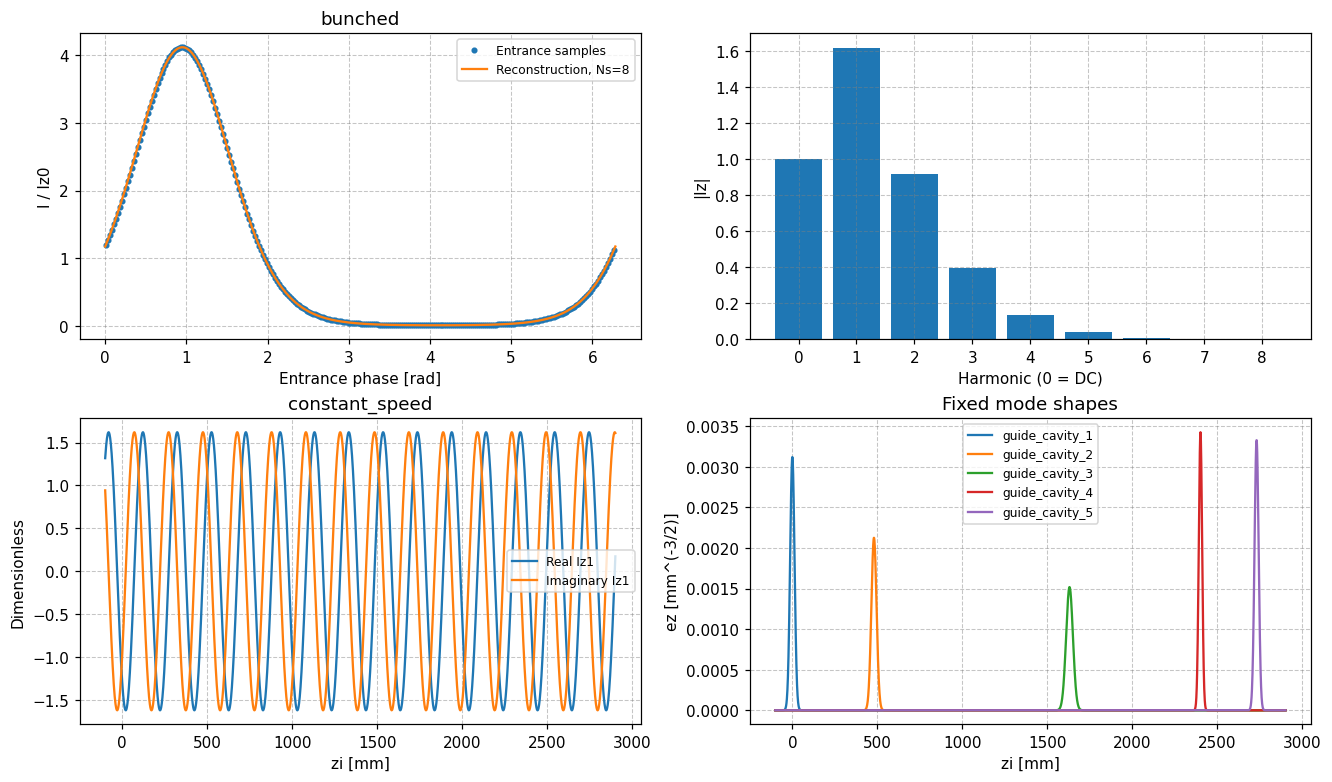

In [7]:
if beam_transport == "constant_speed":
    phase_advance = np.exp(-1.0j * np.outer(grid.z - grid.z[0], np.arange(1, Ns + 1)))
    beam_state.Iz[:] *= phase_advance
    beam_state.QQ[:] *= phase_advance
elif beam_transport != "initial_guess":
    raise ValueError("Choose initial_guess or constant_speed.")

show_table([
    ("case_name", case_name, "-", "Prescribed current distribution"),
    ("beam_transport", beam_transport, "-", "Longitudinal phase prescription"),
    ("I0", reference.I0, "A", "Mean current magnitude"),
    ("U0", reference.U0, "kV", "Constant beam energy"),
    ("drivefactor", drivefactor, "1", "Incident voltage ramp factor"),
    ("Nc", Nc, "cavities", "Global system contains 2*Nc unknowns"),
    ("nh", nh, "harmonic", "Harmonic sampled by each cavity"),
])

phase_plot = np.linspace(0.0, 2.0 * np.pi, 600)
current_waveform = beam_state.IzDC[0] + np.imag(
    np.exp(1.0j * np.outer(phase_plot, np.arange(1, Ns + 1))) @ beam_state.Iz[0]
)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
axes[0, 0].plot(np.mod(tn1, 2*np.pi), Izt / reference.Iz0, ".", label="Entrance samples")
axes[0, 0].plot(phase_plot, current_waveform, label=f"Reconstruction, Ns={Ns}")
axes[0, 0].set(xlabel="Entrance phase [rad]", ylabel="I / Iz0", title=case_name)
harmonics = np.arange(Ns + 1)
Iz_plot = np.r_[beam_state.IzDC[0], beam_state.Iz[0]]
axes[0, 1].bar(harmonics, np.abs(Iz_plot))
axes[0, 1].set(xlabel="Harmonic (0 = DC)", ylabel="|Iz|", xticks=harmonics)
axes[1, 0].plot(grid.zi, beam_state.Iz[:, 0].real, label="Real Iz1")
axes[1, 0].plot(grid.zi, beam_state.Iz[:, 0].imag, label="Imaginary Iz1")
axes[1, 0].set(xlabel="zi [mm]", ylabel="Dimensionless", title=beam_transport)
for k, name in enumerate(cavities.names):
    axes[1, 1].plot(grid.zi, cavity_fields.ez[:, k], label=name)
axes[1, 1].set(xlabel="zi [mm]", ylabel="ez [mm^(-3/2)]", title="Fixed mode shapes")
for ax in (axes[0, 0], axes[1, 0], axes[1, 1]):
    ax.legend(fontsize=8)
plt.show()


## 4. Assemble and solve the global circuit

\[
Mc\,\mathbf x=B,\qquad
\mathbf x=(V_{np,1},V_{nc,1},\ldots,V_{np,N_c},V_{nc,N_c})^T.
\]

`initialize()` allocates the state and computes `Vin`. `solve()` calls `assemble_Mc_B()` and solves the system without changing `flagVnc`. `IterationControl` manages that comparison voltage between nonlinear iterations; it remains zero in this standalone first-solve test.

For cavity \(k\), the normalized beam-drive term is

\[
I_{\mathrm{beam},k}=-e_{\mathrm{sign}}N_{\mathrm{beam}}
\int C3_k(z)\,Iz_{nh_k}(z)\,dz.
\]

The integration coordinate is normalized **z**, not zi in mm. The integrand is a direct product, not a complex-conjugate inner product.


Unknown order: Vnp1, Vnc1, Vnp2, Vnc2, Vnp3, Vnc3, Vnp4, Vnc4, Vnp5, Vnc5
Mc =
 [[-1.827567e+01-2.238124e-15j -1.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j
   0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j
   0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j]
 [ 5.471757e-02+6.700969e-18j -6.087168e-05-0.000000e+00j  0.000000e+00+0.000000e+00j  0.000000e+00-0.000000e+00j
   0.000000e+00+0.000000e+00j  0.000000e+00-0.000000e+00j  0.000000e+00+0.000000e+00j  0.000000e+00-0.000000e+00j
   0.000000e+00+0.000000e+00j  0.000000e+00-0.000000e+00j]
 [ 0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j  1.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j
   0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j
   0.000000e+00+0.000000e+00j  0.000000e+00+0.000000e+00j]
 [ 0.000000e+00+0.000000e+00j  0.000000e+00-0.000000e+00j  

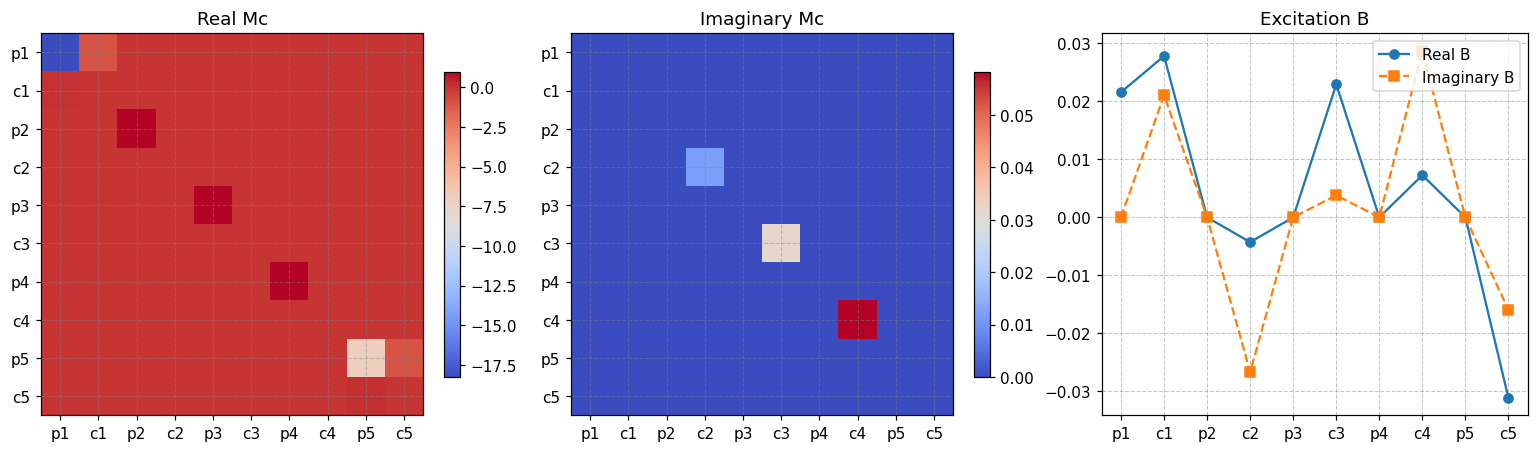

In [8]:
cavity_state = CavityState.initialize(numerical, cavities, beam, reference)
cavity_state.solve(
    numerical, cavities, cavity_fields, beam, beam_state, grid, drivefactor
)

Ibeam = np.zeros(Nc, dtype=complex)
for k in range(Nc):
    Ibeam[k] = -esign * Nbeam * np.trapezoid(
        cavity_fields.C3[:, k] * beam_state.Iz[:, nh[k] - 1], x=grid.z
    )

print("Unknown order:", ", ".join(f"Vnp{k+1}, Vnc{k+1}" for k in range(Nc)))
print("Mc =\n", cavity_state.Mc)
print("B =\n", cavity_state.B)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
labels = [label for k in range(Nc) for label in (f"p{k+1}", f"c{k+1}")]
for ax, values, title in (
    (axes[0], cavity_state.Mc.real, "Real Mc"),
    (axes[1], cavity_state.Mc.imag, "Imaginary Mc"),
):
    im = ax.imshow(values, cmap="coolwarm", aspect="equal")
    ax.set(xticks=np.arange(2*Nc), yticks=np.arange(2*Nc),
           xticklabels=labels, yticklabels=labels, title=title)
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[2].plot(np.arange(2*Nc), cavity_state.B.real, "o-", label="Real B")
axes[2].plot(np.arange(2*Nc), cavity_state.B.imag, "s--", label="Imaginary B")
axes[2].set(xticks=np.arange(2*Nc), xticklabels=labels, title="Excitation B")
axes[2].legend()
plt.show()


## 5. Scale the fields from the circuit solution

The original MATLAB gap-voltage expression (lines 674, 682 and 692) is

\[
Vng_k=U_0\,\frac{V_{nc,k}}{\sqrt{k_{0,k}}}\int ez_k(zi)\,d zi
\quad [\mathrm{kV}].
\]

For the same fixed mode shape, reconstruct its complex longitudinal field coefficient as

\[
Ezc_k(zi)=U_0\frac{V_{nc,k}}{\sqrt{k_{0,k}}}\,ez_k(zi)
\quad [\mathrm{kV/mm}].
\]

**Use k0 in 1/mm here**, not the Gaussian generator's temporary 1/m value.
One kV/mm equals \(10^6\) V/m, or one MV/m.

Group cavities by harmonic to obtain the dimensionless field:

\[
Emz_{\mathrm{reconstructed},m}
=\sum_{k:nh_k=m}\frac{Ezc_k}{\beta_e U_0}
=\sum_{k:nh_k=m}C3_k V_{nc,k}
\frac{1000 U_0}{\eta_0 I_0}.
\]

Thus simply multiplying **C3 by Vnc is not sufficient** with the current normalizations.
Using the solver's imaginary-part convention, a snapshot is

\[
Ezt(zi,\theta)=\beta_e U_0\operatorname{Im}
\sum_m Emz_{\mathrm{reconstructed},m}(zi)e^{im\theta}.
\]

`Ezc` has one column per cavity; `Emz_reconstructed` has one per harmonic; `Ezt` has one per snapshot phase. Cavities at different harmonics are not combined into one phasor. `Vnp` describes a port wave, not a second field to add inside the cavity.


In [9]:
Ezc = cavity_fields.ez * (
    reference.U0 * cavity_state.Vnc / np.sqrt(grid.k0)
)
Vng = reference.U0 * cavity_state.Vnc / np.sqrt(grid.k0) * np.trapezoid(
    cavity_fields.ez, x=grid.zi, axis=0
)
Emz_reconstructed = np.zeros((len(grid.z), Ns), dtype=complex)
for k in range(Nc):
    Emz_reconstructed[:, nh[k] - 1] += Ezc[:, k] / (grid.betae * reference.U0)
Ezt = grid.betae * reference.U0 * np.imag(
    Emz_reconstructed @ np.exp(1.0j * np.outer(np.arange(1, Ns + 1), theta))
)

# Peak phasor convention: power contains 1/2.
power_scale = (reference.U0 * 1000.0)**2 / (2.0 * eta0)
Pport = power_scale * np.abs(cavity_state.Vnp)**2
Pwall = power_scale * np.abs(cavity_state.Vnc)**2 / Qin
Pout = np.where(type == -1, (1.0 - np.abs(gaman)**2) * Pport, 0.0)
RtoQ_grid = eta0 / grid.k0 * np.abs(
    np.trapezoid(cavity_fields.ez, x=grid.zi, axis=0)
)**2

table = [
    "| Cavity | Type | Ibeam | Vnp | Vnc | Vng [kV] | Pwall [W] | Pout [W] |",
    "|---|---|---|---|---|---|---|---|",
]
for k, name in enumerate(cavities.names):
    table.append(
        f"| {name} | {type[k]} | {Ibeam[k]:.5g} | {cavity_state.Vnp[k]:.5g} "
        f"| {cavity_state.Vnc[k]:.5g} | {Vng[k]:.5g} | {Pwall[k]:.5g} | {Pout[k]:.5g} |"
    )
display(Markdown("\n".join(table)))
print("Pport is the reflected wave for input cavities and the outgoing wave for outputs.")
print("Pout includes the output reflection factor; zero entries mark non-output cavities.")
print("Prescribed-beam results are not a converged output-power or efficiency prediction.")


| Cavity | Type | Ibeam | Vnp | Vnc | Vng [kV] | Pwall [W] | Pout [W] |
|---|---|---|---|---|---|---|---|
| guide_cavity_1 | 0 | 0.027782+0.021071j | 0.49875+0.37741j | -9.1365-6.8974j | -1145.9-865.04j | 3.4303e+05 | 0 |
| guide_cavity_2 | 1 | -0.0042745-0.026693j | 0-0j | -2.2362+0.36783j | -224.31+36.897j | 11172 | 0 |
| guide_cavity_3 | 1 | 0.022961+0.003804j | 0-0j | 0.11961-0.72921j | 11.206-68.316j | 1185 | 0 |
| guide_cavity_4 | 1 | 0.0072778+0.028756j | 0-0j | 0.49351-0.12544j | 50.887-12.934j | 657.03 | 0 |
| guide_cavity_5 | -1 | -0.031159-0.01595j | -0.21958-0.1124j | 1.5527+0.79479j | 193.39+98.993j | 8847.8 | 2.6167e+06 |

Pport is the reflected wave for input cavities and the outgoing wave for outputs.
Pout includes the output reflection factor; zero entries mark non-output cavities.
Prescribed-beam results are not a converged output-power or efficiency prediction.


## 6. Voltages and reconstructed RF fields

Field magnitudes show the spatial envelope; real/imaginary parts retain its phase. Snapshot curves show the total instantaneous field at four RF phases. Gap voltage is the **unweighted spatial integral**, not the transit-time-weighted voltage experienced by a moving particle.


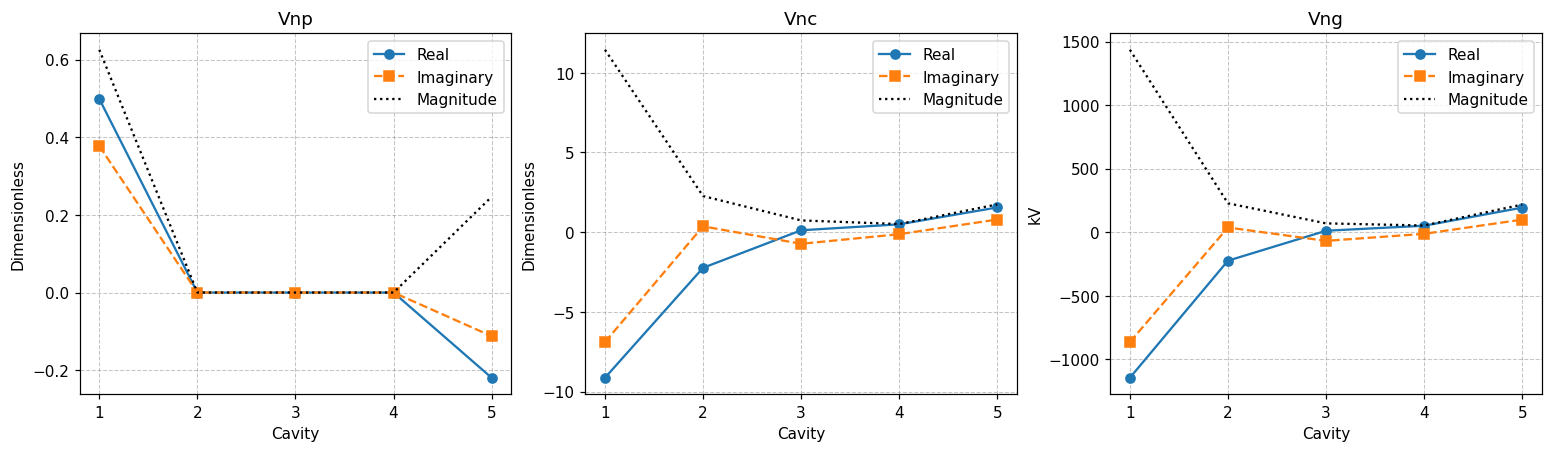

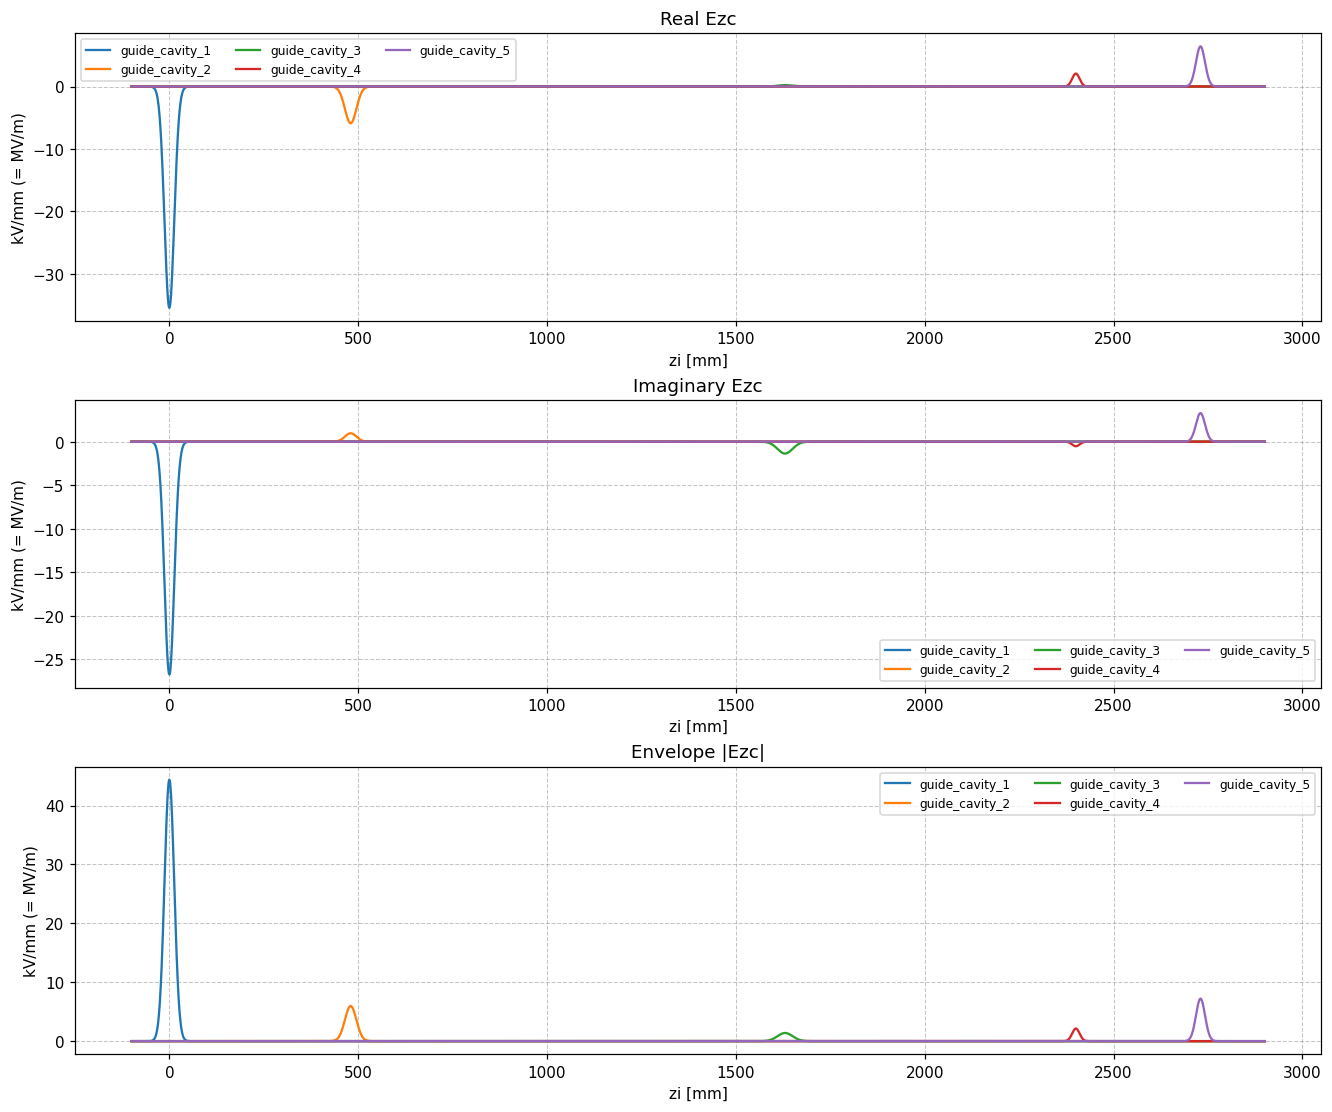

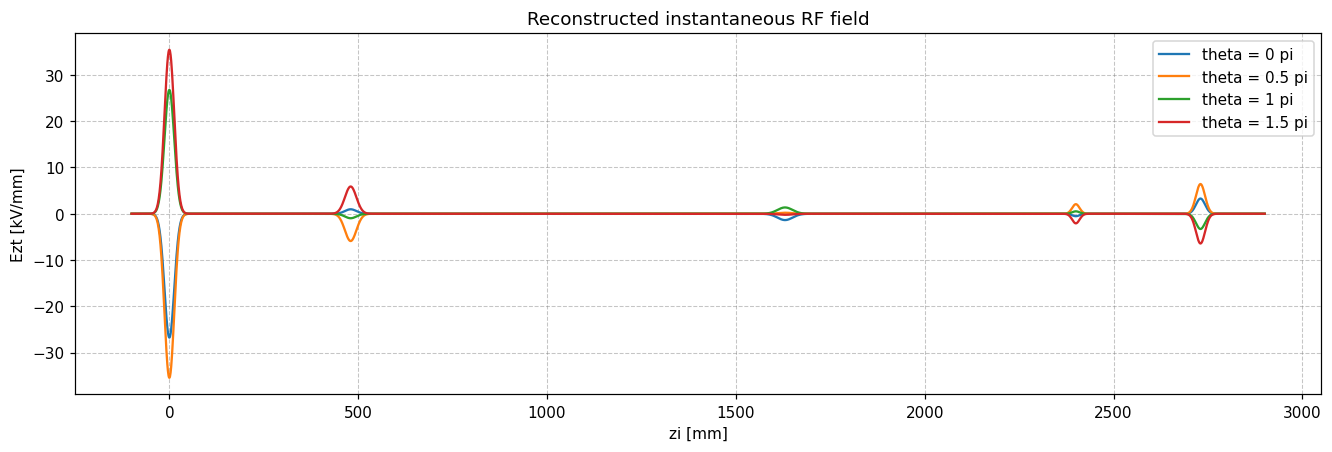

In [10]:
indices = np.arange(1, Nc + 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, name, values, units in (
    (axes[0], "Vnp", cavity_state.Vnp, "Dimensionless"),
    (axes[1], "Vnc", cavity_state.Vnc, "Dimensionless"),
    (axes[2], "Vng", Vng, "kV"),
):
    ax.plot(indices, values.real, "o-", label="Real")
    ax.plot(indices, values.imag, "s--", label="Imaginary")
    ax.plot(indices, np.abs(values), "k:", label="Magnitude")
    ax.set(xlabel="Cavity", xticks=indices, ylabel=units, title=name)
    ax.legend()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(12, 10), layout="constrained")
for k, name in enumerate(cavities.names):
    axes[0].plot(grid.zi, Ezc[:, k].real, label=name)
    axes[1].plot(grid.zi, Ezc[:, k].imag, label=name)
    axes[2].plot(grid.zi, np.abs(Ezc[:, k]), label=name)
for ax, title in zip(axes, ("Real Ezc", "Imaginary Ezc", "Envelope |Ezc|")):
    ax.set(xlabel="zi [mm]", ylabel="kV/mm (= MV/m)", title=title)
    ax.legend(fontsize=8, ncol=3)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
for column, phase in enumerate(theta):
    ax.plot(grid.zi, Ezt[:, column], label=f"theta = {phase/np.pi:g} pi")
ax.set(xlabel="zi [mm]", ylabel="Ezt [kV/mm]", title="Reconstructed instantaneous RF field")
ax.legend()
plt.show()


## 7. Internal checks

Check the linear-system residual, complex superposition of beam and external excitation, square-root power scaling, and field normalization. When off-diagonal coupling is zero, also compare the global solution with separate 2×2 solves. For an externally driven uncoupled input cavity, use the explicit loaded-cavity formula as an additional check.

These checks do not replace the independent MATLAB comparison. They do not test energy conservation of a self-consistently evolving beam.


In [11]:
solution = np.empty(2 * Nc, dtype=complex)
solution[0::2] = cavity_state.Vnp
solution[1::2] = cavity_state.Vnc
np.testing.assert_allclose(cavity_state.Mc @ solution, cavity_state.B, rtol=1e-10, atol=1e-12)
np.testing.assert_array_equal(cavity_state.flagVnc, np.zeros(Nc))
np.testing.assert_allclose(np.trapezoid(Ezc, x=grid.zi, axis=0), Vng, rtol=1e-10, atol=1e-12)

Emz_from_C3 = np.zeros_like(Emz_reconstructed)
for k in range(Nc):
    Emz_from_C3[:, nh[k] - 1] += (
        cavity_fields.C3[:, k] * cavity_state.Vnc[k]
        * reference.U0 * 1000.0 / (eta0 * reference.I0)
    )
np.testing.assert_allclose(Emz_reconstructed, Emz_from_C3, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(
    np.abs(1000.0 * Vng)**2, 2.0 * Pwall * Qin * RtoQ_grid,
    rtol=1e-10, atol=1e-12,
)
np.testing.assert_allclose(
    power_scale * np.abs(cavity_state.Vin * drivefactor)**2,
    Pin * drivefactor**2, rtol=1e-10, atol=1e-12,
)

solutions = {}
for label, power_factor, current_factor in (
    ("external", 1.0, 0.0), ("beam", 0.0, 1.0), ("four_power", 4.0, 0.0)
):
    cavities_test = replace(cavities, Pin=power_factor * cavities.Pin)
    beam_test = replace(beam_state, Iz=current_factor * beam_state.Iz)
    circuit_test = CavityState.initialize(numerical, cavities_test, beam, reference)
    circuit_test.solve(numerical, cavities_test, cavity_fields, beam, beam_test, grid, drivefactor)
    solutions[label] = circuit_test
for name in ("Vnp", "Vnc"):
    np.testing.assert_allclose(
        getattr(cavity_state, name),
        getattr(solutions["external"], name) + getattr(solutions["beam"], name),
        rtol=1e-10, atol=1e-12,
    )
    np.testing.assert_allclose(
        getattr(solutions["four_power"], name), 2.0 * getattr(solutions["external"], name),
        rtol=1e-10, atol=1e-12,
    )

off_diagonal = kai.copy()
np.fill_diagonal(off_diagonal, 0.0)
if not np.any(off_diagonal):
    separate = np.zeros_like(solution)
    for k in range(Nc):
        block = slice(2*k, 2*k + 2)
        separate[block] = np.linalg.solve(cavity_state.Mc[block, block], cavity_state.B[block])
        if type[k] == 0:
            Dk = 1.0 / Qin[k] + 2.0j * (nh[k]*grid.w-grid.w0[k])/grid.w0[k] + 2.0j*kai[k, k]
            expected_Vnc = (
                2.0 * np.exp(1.0j * Lsb[k]) * cavity_state.Vin[k] * drivefactor
                / np.sqrt(Qext[k]) / (Dk + 1.0/Qext[k])
            )
            np.testing.assert_allclose(solutions["external"].Vnc[k], expected_Vnc,
                                       rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(solution, separate, rtol=1e-10, atol=1e-12)

print(f"Residual norm: {np.linalg.norm(cavity_state.Mc @ solution - cavity_state.B):.3e}")
print("PASS: circuit, superposition, power scaling, and reconstructed-field checks.")


Residual norm: 1.337e-15
PASS: circuit, superposition, power scaling, and reconstructed-field checks.


## 8. Export this case

The final cell overwrites only this folder's `inputs.mat` and `python_results.mat`. MATLAB receives **raw parameters and sample weights**, never Python-computed fields, harmonics or matrices. `Y0+1` is exported for MATLAB indexing; real integer inputs become doubles.

Each export gets a new `run_id`, copied through the independent MATLAB calculation. The comparison rejects results from different exports, so rerun MATLAB whenever Python inputs/results are regenerated. The ID is a run-pairing token, not a checksum of subsequently edited files.

The files hold one selected case. Inspect and compare it before switching presets.


In [13]:
run_id = uuid4().hex
inputs = {
    **vars(beam), **vars(cavities), **vars(tube), **vars(numerical),
    "RtoQ": RtoQ, "M": M, "N": N, "Nr": Nr, "factorregion": factorregion,
    "case_name": case_name, "beam_transport": beam_transport,
    "mono": mono, "nn": nn, "Npin": Npin, "moviedisp": moviedisp,
    "theta": theta, "run_id": run_id,
    "c": c, "etom": etom, "mu01": mu01,
}
inputs["Y0"] = beam.Y0 + 1
for name, value in inputs.items():
    if np.asarray(value).dtype.kind in "iub":
        inputs[name] = np.asarray(value, dtype=float)

python_results = {
    **vars(reference), **vars(cavity_state),
    "w": grid.w, "w0": grid.w0, "k0": grid.k0,
    "betae": grid.betae, "dz": grid.dz, "zi": grid.zi, "z": grid.z, "dt": grid.dt,
    "z_mm": z_mm, "e_z": e_z, "ez": cavity_fields.ez, "C3": cavity_fields.C3,
    "IzDC": beam_state.IzDC, "Iz": beam_state.Iz,
    "Ibeam": Ibeam, "Vng": Vng, "Ezc": Ezc,
    "Emz_reconstructed": Emz_reconstructed, "Ezt": Ezt,
    "Pport": Pport, "Pwall": Pwall, "Pout": Pout, "RtoQ_grid": RtoQ_grid,
    "Nt": Nt, "Ns": Ns, "Nc": Nc, "N": N, "theta": theta,
    "drivefactor": drivefactor, "kai": kai, "gaman": gaman, "Lsb": Lsb,
    "nh": nh, "type": type,
    "case_name": case_name, "beam_transport": beam_transport,
    "cavityname": cavityname, "run_id": run_id,
}
savemat(test_directory / "inputs.mat", inputs, oned_as="row")
savemat(test_directory / "python_results.mat", python_results, oned_as="row")
print("Saved:", test_directory / "inputs.mat")
print("Saved:", test_directory / "python_results.mat")
print("Next: run cavity_circuit_test.mlx in MATLAB, then compare_results.ipynb.")


Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\5.cavity_circuit_test\inputs.mat
Saved: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\5.cavity_circuit_test\python_results.mat
Next: run cavity_circuit_test.mlx in MATLAB, then compare_results.ipynb.
